# Bean Leaf Disease Classification – End-to-End MLOps Pipeline
**Author:** Sandrine Umugwaneza

**Problem:** Bean is a staple crop in Rwanda and East Africa. Diseases like Angular Leaf Spot and Bean Rust reduce yields, and many farmers cannot access an agronomist quickly. This project builds an image classifier that diagnoses a bean leaf from a smartphone photo.

**Dataset:** iBean – Makerere AI Lab (2020), annotated by NaCRRI experts, Uganda. 3 classes: angular_leaf_spot, bean_rust, healthy.
Source: https://github.com/AI-Lab-Makerere/ibean/

## 1. Data Exploration & Visualizations

### 1.1 Data Acquisition
The dataset is downloaded from Hugging Face (`AI-Lab-Makerere/beans`) and every image is saved as a `.jpg` file in the project folder structure:

- `data/train/<class_name>/` – training images (original train + validation splits; a validation set is split off later)
- `data/test/<class_name>/` – held-out test images, never used during training

We then count the images per class to check the dataset size and balance.

In [1]:
# Step 1: Data acquisition
!pip install -q datasets

import os
from datasets import load_dataset

# Download the bean leaf dataset from Hugging Face
ds = load_dataset("AI-Lab-Makerere/beans")
class_names = ds["train"].features["labels"].names
print("Classes:", class_names)

def save_split(split, out_dir):
    """Save each image as a .jpg inside out_dir/<class_name>/"""
    for i, row in enumerate(ds[split]):
        label = class_names[row["labels"]]
        folder = os.path.join(out_dir, label)
        os.makedirs(folder, exist_ok=True)
        row["image"].convert("RGB").save(os.path.join(folder, f"{split}_{i}.jpg"))

# train + validation go into data/train (we split validation off in the notebook)
save_split("train", "data/train")
save_split("validation", "data/train")
save_split("test", "data/test")

# Count the images per class
for split in ["data/train", "data/test"]:
    print(split)
    for c in class_names:
        print(f"   {c}: {len(os.listdir(os.path.join(split, c)))} images")

README.md:   0%|          | 0.00/4.95k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  144MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.5MB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 17.7MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/1034 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/133 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/128 [00:00<?, ? examples/s]

Classes: ['angular_leaf_spot', 'bean_rust', 'healthy']
data/train
   angular_leaf_spot: 389 images
   bean_rust: 393 images
   healthy: 385 images
data/test
   angular_leaf_spot: 43 images
   bean_rust: 43 images
   healthy: 42 images


### 1.2 Visual Inspection of Sample Images
Before measuring anything, we look at 4 random images from each class to understand what the model will see.

**Observations:**
- **Angular leaf spot:** small brown, angular lesions limited by the leaf veins, sometimes with yellowing.
- **Bean rust:** small round reddish-brown pustules, often with a yellow halo.
- **Healthy:** uniform green leaves with no spots.
- The photos were taken **in the field** with smartphones, so they also contain soil, grass, other plants and hands. The model must learn to focus on the leaf, not the background.

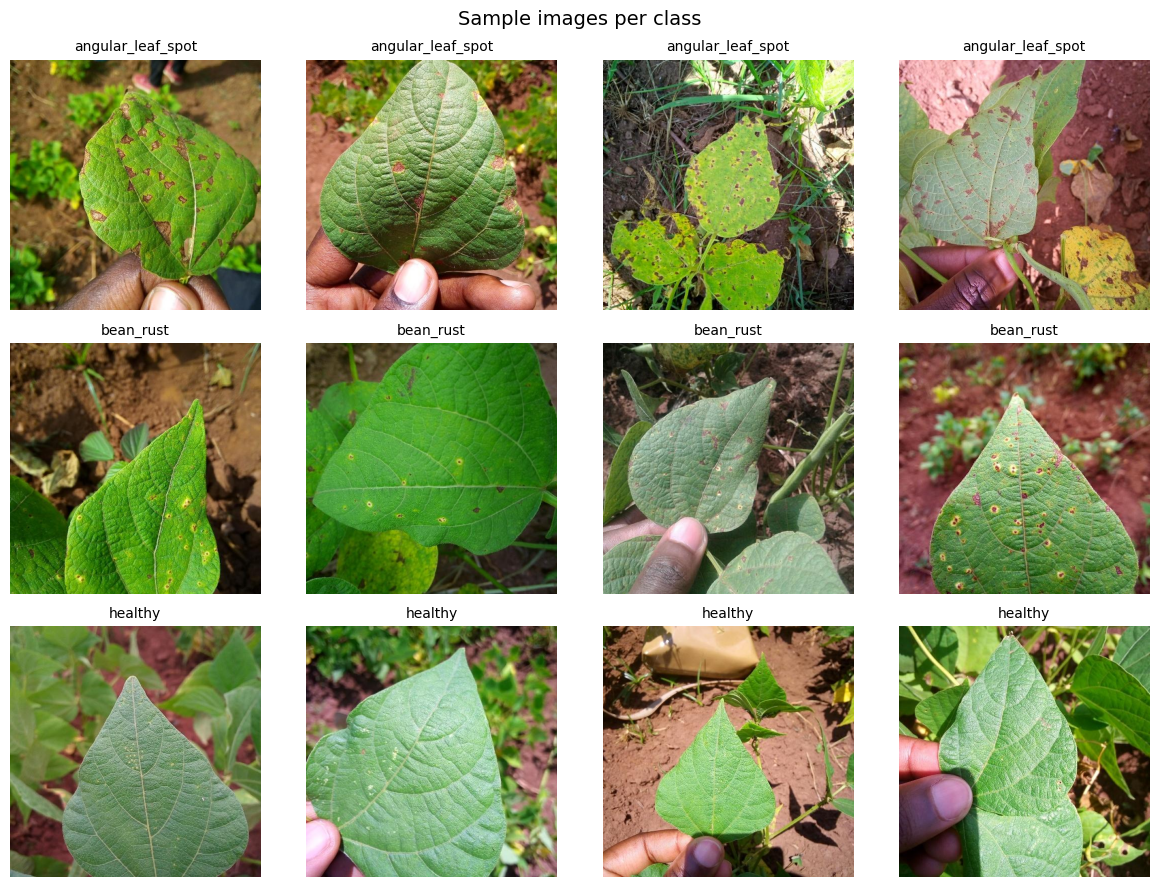

In [2]:
import os, glob, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageFilter

TRAIN_DIR = "data/train"
TEST_DIR = "data/test"
CLASS_NAMES = ["angular_leaf_spot", "bean_rust", "healthy"]

# Show 4 random images from each class
fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for row, cls in enumerate(CLASS_NAMES):
    files = random.sample(glob.glob(f"{TRAIN_DIR}/{cls}/*.jpg"), 4)
    for col, f in enumerate(files):
        axes[row, col].imshow(Image.open(f))
        axes[row, col].axis("off")
        axes[row, col].set_title(cls, fontsize=10)
plt.suptitle("Sample images per class", fontsize=14)
plt.tight_layout()
plt.show()

### 1.3 Extracting Features from the Images
Images do not have columns like a table, so we **measure numeric features** from each image (resized to 128×128 for speed):

| Feature | How it is measured | Why it matters |
|---|---|---|
| **Green ratio** | mean green ÷ (mean red + green + blue) | Diseases turn leaf tissue yellow/brown, reducing green |
| **Brightness** | mean pixel value of the grayscale image (0–255) | Reveals lighting differences between classes (possible bias) |
| **Edge density** | share of pixels detected as edges | Lesions and spots could add texture/edges |

We also record each image's width and height to check whether resizing will be uniform.

In [3]:
def image_features(path):
    """Measure simple visual features from one image."""
    img = Image.open(path).convert("RGB").resize((128, 128))
    arr = np.asarray(img, dtype=np.float32)
    r, g, b = arr[..., 0].mean(), arr[..., 1].mean(), arr[..., 2].mean()

    gray_img = img.convert("L")
    gray = np.asarray(gray_img, dtype=np.float32)
    edges = np.asarray(gray_img.filter(ImageFilter.FIND_EDGES), dtype=np.float32)

    return {
        "green_ratio": g / (r + g + b + 1e-6),   # share of green in the colour
        "brightness": gray.mean(),               # 0 = black, 255 = white
        "edge_density": (edges > 40).mean(),     # share of pixels that are edges/spots
        "width": Image.open(path).size[0],
        "height": Image.open(path).size[1],
    }

rows = []
for cls in CLASS_NAMES:
    for f in glob.glob(f"{TRAIN_DIR}/{cls}/*.jpg"):
        feats = image_features(f)
        feats["class"] = cls
        rows.append(feats)

df = pd.DataFrame(rows)
print(df.shape)
print("\nImage sizes found:", df.groupby(["width", "height"]).size().to_dict())
print("\nAverage features per class:")
print(df.groupby("class")[["green_ratio", "brightness", "edge_density"]].mean().round(3))

(1167, 6)

Image sizes found: {(500, 500): 1167}

Average features per class:
                   green_ratio  brightness  edge_density
class                                                   
angular_leaf_spot        0.403  125.702003         0.280
bean_rust                0.380  115.539001         0.277
healthy                  0.412  129.621002         0.292


### 1.4 Visualizing the Class Distribution and Features
- **Bar chart:** number of training images per class (checks class balance).
- **Box plots:** distribution of each feature per class. The line in the box is the median, the box covers the middle 50% of images, and the dots are outliers. If the boxes of two classes overlap a lot, that feature alone cannot separate those classes.

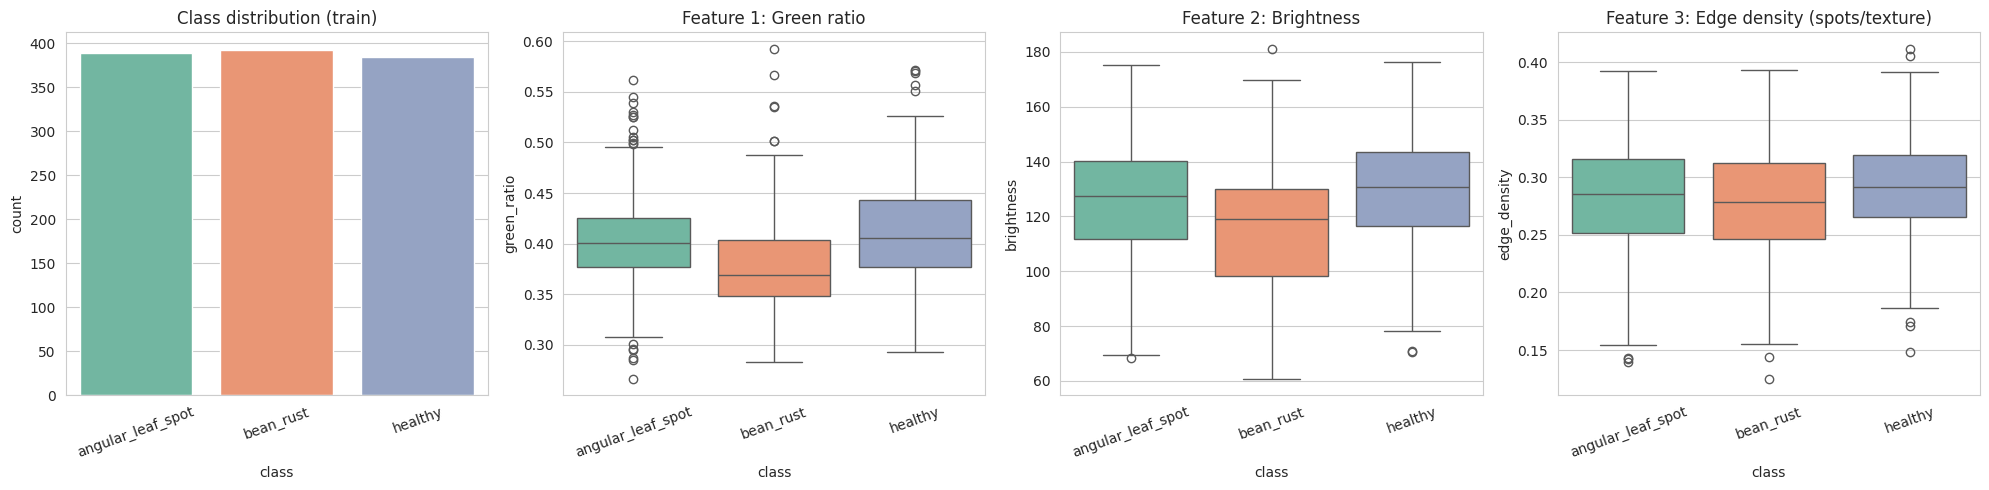

In [7]:
sns.set_style("whitegrid")
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

# Class distribution
sns.countplot(data=df, x="class", hue="class", legend=False,
              order=CLASS_NAMES, ax=axes[0], palette="Set2")
axes[0].set_title("Class distribution (train)")
axes[0].tick_params(axis="x", rotation=20)

# Feature 1, 2, 3
features = ["green_ratio", "brightness", "edge_density"]
titles = ["Feature 1: Green ratio", "Feature 2: Brightness", "Feature 3: Edge density (spots/texture)"]

for ax, feat, title in zip(axes[1:], features, titles):
    sns.boxplot(data=df, x="class", y=feat, hue="class", legend=False,
                order=CLASS_NAMES, ax=ax, palette="Set2")
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

### 1.5 What the data tells us

**Class balance:** The three classes are almost equal (385–393 images each), so the model won't favour one class and accuracy is a fair metric. All images are 500×500.

**Green ratio:** Healthy leaves are the greenest (0.412) and bean rust the least green (0.380), which makes sense since rust leaves brown pustules. But the boxes overlap a lot, because the photos also show soil, grass and hands. Colour alone can't diagnose a leaf.

**Brightness:** Bean rust photos are darker (115.5 vs 129.6 for healthy). This could be the disease, but it could also be shade or time of day when the photo was taken. I don't want the model to learn "dark photo = rust", so I'll add brightness augmentation during training.

**Edge density:** I expected diseased leaves to have more edges because of the spots, but all three classes are nearly the same (0.28–0.29). Leaf veins and the background create most of the edges, and the lesions are small.

**The story:** The dataset is clean and balanced, but the differences between classes are subtle and mixed with background noise. Simple measurements aren't enough, which is why I use a pretrained CNN (MobileNetV2) that can learn the small lesion patterns, plus augmentation to handle lighting and background.

## 2. Data Preprocessing

Steps applied before training:
1. **Load & resize** – every image is resized from 500×500 to 224×224 (the input size of MobileNetV2).
2. **Train / validation / test split** – 85% of `data/train` for training, 15% for validation (used for early stopping). `data/test` stays untouched until the final evaluation.
3. **Normalization** – pixel values are scaled from [0, 255] to [-1, 1], the range MobileNetV2 was pretrained on.
4. **Data augmentation** – random flips, rotations, zoom, brightness and contrast changes on training images only, so the model learns the disease instead of the lighting or leaf position.
5. **Performance** – caching and prefetching so the GPU never waits for data.

In [8]:
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

# Training set (85% of data/train)
train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    validation_split=0.15,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
)

# Validation set (15% of data/train)
val_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    validation_split=0.15,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
)

# Test set (kept in order so we can compare predictions with true labels later)
test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

print("\nClass names:", train_ds.class_names)
print("TensorFlow version:", tf.__version__)

Found 1167 files belonging to 3 classes.
Using 992 files for training.
Found 1167 files belonging to 3 classes.
Using 175 files for validation.
Found 128 files belonging to 3 classes.

Class names: ['angular_leaf_spot', 'bean_rust', 'healthy']
TensorFlow version: 2.21.0


### 2.2 Normalization
MobileNetV2 was pretrained on images scaled to [-1, 1]. A `Rescaling` layer does this: `pixel / 127.5 - 1`.

I put this layer **inside the model** (in Section 3), so the saved model normalizes images by itself. That way the API only needs to resize an uploaded photo, and training and prediction always use exactly the same preprocessing.

In [9]:
normalization = tf.keras.layers.Rescaling(1.0 / 127.5, offset=-1)

images, labels = next(iter(train_ds))
print("Batch shape:", images.shape)          # (32, 224, 224, 3)
print("Labels in this batch:", labels.numpy()[:10])
print(f"Before normalization: min={images.numpy().min():.1f}, max={images.numpy().max():.1f}")

normalized = normalization(images)
print(f"After normalization:  min={normalized.numpy().min():.2f}, max={normalized.numpy().max():.2f}")

Batch shape: (32, 224, 224, 3)
Labels in this batch: [0 1 1 2 0 1 0 0 0 2]
Before normalization: min=0.0, max=255.0
After normalization:  min=-1.00, max=1.00


### 2.3 Data Augmentation
The dataset is small (~1,000 training images), and Section 1 showed that bean rust photos are darker. Augmentation creates new variations of each image **during training only**:

- **RandomFlip** and **RandomRotation** – a leaf can be photographed from any angle.
- **RandomZoom** – the leaf can be near or far from the camera.
- **RandomBrightness** and **RandomContrast** – removes the lighting shortcut, so the model can't learn "dark photo = rust".

This acts as **regularization** and reduces overfitting.

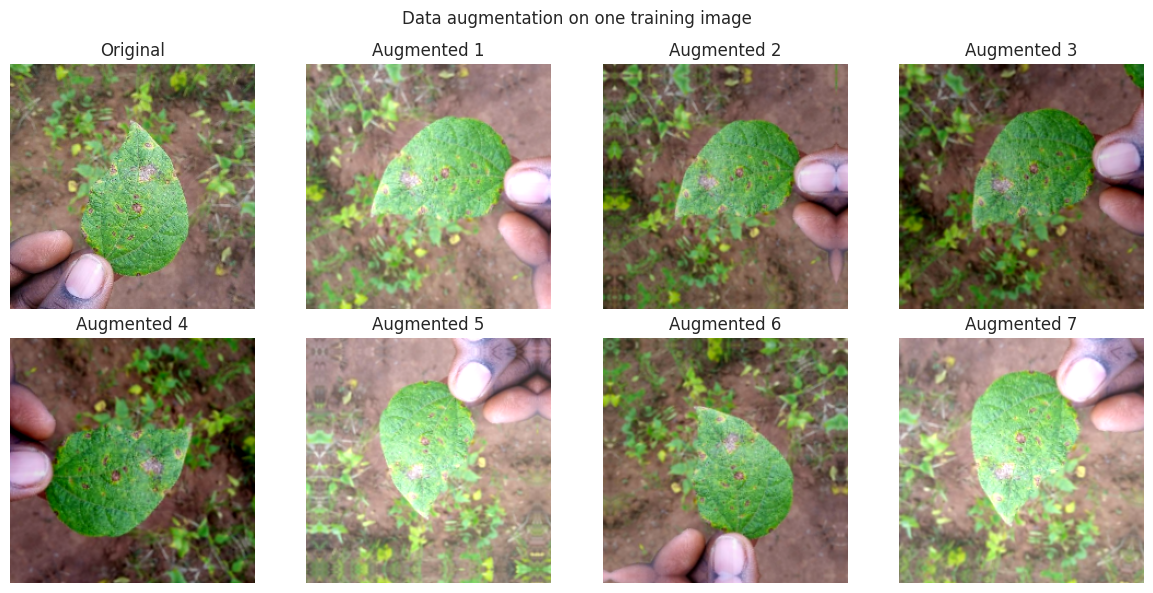

In [10]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal_and_vertical"),
    tf.keras.layers.RandomRotation(0.2),
    tf.keras.layers.RandomZoom(0.2),
    tf.keras.layers.RandomBrightness(0.2, value_range=(0, 255)),
    tf.keras.layers.RandomContrast(0.2),
], name="data_augmentation")

# Show one image augmented 8 different ways
sample = images[:1]
plt.figure(figsize=(12, 6))
for i in range(8):
    augmented = data_augmentation(sample, training=True)
    plt.subplot(2, 4, i + 1)
    plt.imshow(np.clip(augmented[0].numpy(), 0, 255).astype("uint8"))
    plt.title("Original" if i == 0 else f"Augmented {i}")
    plt.axis("off")
    if i == 0:
        plt.imshow(sample[0].numpy().astype("uint8"))
plt.suptitle("Data augmentation on one training image")
plt.tight_layout()
plt.show()

### 2.4 Performance Optimization
- `cache()` keeps the images in memory after the first epoch, so they aren't re-read from disk.
- `shuffle()` mixes the batch order each epoch.
- `prefetch()` prepares the next batch while the GPU trains on the current one.

In [11]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.cache().shuffle(100, seed=SEED).prefetch(AUTOTUNE)
val_ds = val_ds.cache().prefetch(AUTOTUNE)
test_ds = test_ds.cache().prefetch(AUTOTUNE)

print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Test batches:", tf.data.experimental.cardinality(test_ds).numpy())

Training batches: 31
Validation batches: 6
Test batches: 4


## 3. Model Creation

I use **transfer learning** with **MobileNetV2** pretrained on ImageNet. It is small and fast (good for deployment on a free cloud server) but still accurate.

**Architecture:**
Input (224×224×3) → Data augmentation → Rescaling to [-1, 1] → MobileNetV2 (frozen) → Global Average Pooling → Dropout (0.3) → Dense (3, softmax, L2 regularization)

**Optimization techniques used:**
| Technique | Why |
|---|---|
| Pretrained model (MobileNetV2) | Reuses features learned on 1.4M images, so it needs less data |
| Data augmentation | Regularization: the model sees new variations each epoch |
| Dropout (0.3) | Regularization: prevents relying on a few neurons |
| L2 regularization | Keeps weights small to reduce overfitting |
| Adam optimizer | Adaptive learning rate, converges fast |
| Early stopping | Stops when validation loss stops improving and keeps the best weights |
| ReduceLROnPlateau | Lowers the learning rate when progress stalls |
| Fine-tuning | Unfreezes the top MobileNetV2 layers with a very small learning rate |

In [12]:
NUM_CLASSES = len(CLASS_NAMES)

# Pretrained base model (without its original 1000-class top layer)
base_model = tf.keras.applications.MobileNetV2(
    input_shape=IMG_SIZE + (3,),
    include_top=False,
    weights="imagenet",
)
base_model.trainable = False   # Phase 1: freeze the pretrained layers

# Full model
inputs = tf.keras.Input(shape=IMG_SIZE + (3,))
x = data_augmentation(inputs)                    # only active during training
x = tf.keras.layers.Rescaling(1.0 / 127.5, offset=-1)(x)
x = base_model(x, training=False)                # keep BatchNorm in inference mode
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)
outputs = tf.keras.layers.Dense(
    NUM_CLASSES,
    activation="softmax",
    kernel_regularizer=tf.keras.regularizers.l2(1e-4),
)(x)

model = tf.keras.Model(inputs, outputs, name="bean_disease_mobilenetv2")
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "bean_disease_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

### 3.2 Training – Phase 1 (frozen base)
Only the new top layers are trained, with Adam (learning rate 0.001).
**Callbacks:**
- `EarlyStopping` – stops after 5 epochs without improvement in validation loss and restores the best weights.
- `ReduceLROnPlateau` – halves the learning rate if validation loss stalls for 2 epochs.

In [13]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, verbose=1),
]

EPOCHS_PHASE1 = 20
history1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_PHASE1,
    callbacks=callbacks,
)

Epoch 1/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 15s 167ms/step - accuracy: 0.5575 - loss: 0.9532 - val_accuracy: 0.7429 - val_loss: 0.6463 - learning_rate: 0.0010
Epoch 2/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 2s 63ms/step - accuracy: 0.7218 - loss: 0.6484 - val_accuracy: 0.7429 - val_loss: 0.5821 - learning_rate: 0.0010
Epoch 3/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 3s 63ms/step - accuracy: 0.7843 - loss: 0.5274 - val_accuracy: 0.7829 - val_loss: 0.5171 - learning_rate: 0.0010
Epoch 4/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 2s 68ms/step - accuracy: 0.8085 - loss: 0.4871 - val_accuracy: 0.8114 - val_loss: 0.4635 - learning_rate: 0.0010
Epoch 5/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 2s 75ms/step - accuracy: 0.8226 - loss: 0.4562 - val_accuracy: 0.8229 - val_loss: 0.4396 - learning_rate: 0.0010
Epoch 6/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 2s 61ms/step - accuracy: 0.8407 - loss: 0.4057 - val_accuracy: 0.8057 - val_loss: 0.4525 - learning_rate: 0.0010
Epoch 7/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 2s 63ms/step - accuracy: 0.8327 - loss: 0.4178 - val_a

### 3.3 Training – Phase 2 (fine-tuning)
The last 30 layers of MobileNetV2 are unfrozen and trained with a much smaller learning rate (0.00001), so the pretrained features adapt to bean leaves without being destroyed.

In [14]:
base_model.trainable = True
for layer in base_model.layers[:-30]:     # keep all but the last 30 layers frozen
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

start_epoch = len(history1.history["loss"])
EPOCHS_PHASE2 = 10
history2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=start_epoch + EPOCHS_PHASE2,
    initial_epoch=start_epoch,
    callbacks=callbacks,
)

Epoch 21/30
31/31 ━━━━━━━━━━━━━━━━━━━━ 14s 148ms/step - accuracy: 0.7954 - loss: 0.5223 - val_accuracy: 0.8457 - val_loss: 0.3572 - learning_rate: 1.0000e-05
Epoch 22/30
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - accuracy: 0.8240 - loss: 0.4303
Epoch 22: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-06.
31/31 ━━━━━━━━━━━━━━━━━━━━ 3s 84ms/step - accuracy: 0.8196 - loss: 0.4449 - val_accuracy: 0.8629 - val_loss: 0.3687 - learning_rate: 1.0000e-05
Epoch 23/30
31/31 ━━━━━━━━━━━━━━━━━━━━ 5s 78ms/step - accuracy: 0.8347 - loss: 0.4150 - val_accuracy: 0.8629 - val_loss: 0.3717 - learning_rate: 5.0000e-06
Epoch 24/30
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.8315 - loss: 0.4132
Epoch 24: ReduceLROnPlateau reducing learning rate to 2.499999936844688e-06.
31/31 ━━━━━━━━━━━━━━━━━━━━ 2s 78ms/step - accuracy: 0.8377 - loss: 0.4008 - val_accuracy: 0.8629 - val_loss: 0.3713 - learning_rate: 5.0000e-06
Epoch 25/30
31/31 ━━━━━━━━━━━━━━━━━━━━ 3s 83ms/step - accuracy: 0.8357 -

### 3.4 Learning Curves
Training vs validation accuracy and loss across both phases. The dashed line marks where fine-tuning starts. If the validation curve follows the training curve closely, the model is not overfitting.

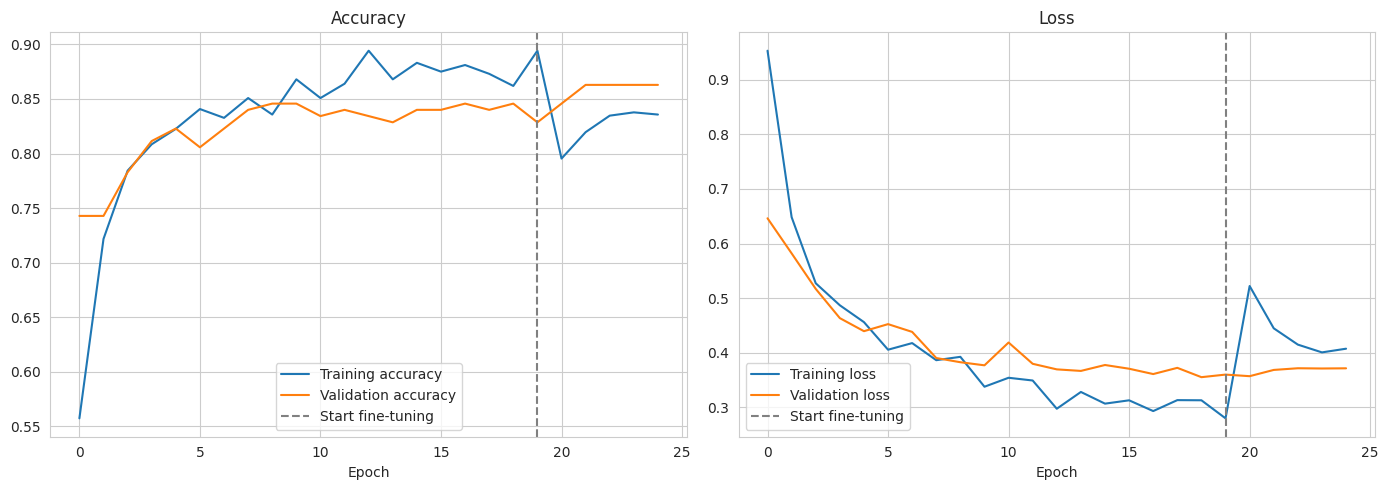

In [15]:
acc = history1.history["accuracy"] + history2.history["accuracy"]
val_acc = history1.history["val_accuracy"] + history2.history["val_accuracy"]
loss = history1.history["loss"] + history2.history["loss"]
val_loss = history1.history["val_loss"] + history2.history["val_loss"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(acc, label="Training accuracy")
axes[0].plot(val_acc, label="Validation accuracy")
axes[0].axvline(start_epoch - 1, color="gray", linestyle="--", label="Start fine-tuning")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(loss, label="Training loss")
axes[1].plot(val_loss, label="Validation loss")
axes[1].axvline(start_epoch - 1, color="gray", linestyle="--", label="Start fine-tuning")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

### 3.5 Saving the Model
Data augmentation is only used during training; at prediction time it does nothing. So I save an **inference model** made of the same trained layers without the augmentation block:

Input → Rescaling → MobileNetV2 → Global Average Pooling → Dropout → Dense (softmax)

It is saved as `models/bean_disease_model.h5` (the format required by the assignment). For retraining, this saved model is loaded as the pretrained starting point and augmentation is added back on top.

In [18]:
# Build the inference model by reusing the trained layers (no augmentation)
inf_inputs = tf.keras.Input(shape=IMG_SIZE + (3,))
x = tf.keras.layers.Rescaling(1.0 / 127.5, offset=-1)(inf_inputs)
x = base_model(x, training=False)
x = model.layers[-3](x)   # GlobalAveragePooling2D (trained)
x = model.layers[-2](x)   # Dropout (trained)
inf_outputs = model.layers[-1](x)   # Dense softmax (trained)

inference_model = tf.keras.Model(inf_inputs, inf_outputs, name="bean_disease_classifier")
inference_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

# Check that both models give the same predictions
test_images, _ = next(iter(test_ds))
same = np.allclose(model.predict(test_images, verbose=0),
                   inference_model.predict(test_images, verbose=0), atol=1e-5)
print("Same predictions as trained model:", same)

# Save
os.makedirs("models", exist_ok=True)
inference_model.save("models/bean_disease_model.h5")
print("Saved:", os.listdir("models"))

# Download to your computer
from google.colab import files
files.download("models/bean_disease_model.h5")

Same predictions as trained model: True
Saved: ['bean_disease_model.h5']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 4. Model Evaluation

The model is evaluated on the **test set** (128 images it has never seen). To prove the saved file works, I load the model back from `models/bean_disease_model.h5`.

**Metrics used:**
| Metric | What it tells us |
|---|---|
| **Accuracy** | Share of all leaves classified correctly |
| **Loss** | Cross-entropy: how confident and correct the predictions are (lower is better) |
| **Precision** | When the model says "bean rust", how often is it right? (avoids false alarms) |
| **Recall** | Of all real bean rust leaves, how many did it find? (avoids missed diseases) |
| **F1-score** | Balance between precision and recall |
| **ROC-AUC** | How well the model separates the classes across all thresholds |

For a farmer, **recall on the disease classes** matters most: missing a sick plant lets the disease spread.

In [19]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, classification_report,
                             confusion_matrix)

# Load the saved model to prove the file works
loaded_model = tf.keras.models.load_model("models/bean_disease_model.h5")

# Loss and accuracy from Keras
test_loss, test_acc = loaded_model.evaluate(test_ds, verbose=0)

# Predictions on the whole test set
y_true = np.concatenate([labels.numpy() for _, labels in test_ds])
y_prob = loaded_model.predict(test_ds, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

metrics = {
    "Accuracy": accuracy_score(y_true, y_pred),
    "Loss": test_loss,
    "Precision (macro)": precision_score(y_true, y_pred, average="macro"),
    "Recall (macro)": recall_score(y_true, y_pred, average="macro"),
    "F1-score (macro)": f1_score(y_true, y_pred, average="macro"),
    "ROC-AUC (one-vs-rest)": roc_auc_score(y_true, y_prob, multi_class="ovr"),
}
metrics_df = pd.DataFrame(metrics, index=["Test set"]).T.round(4)
print(metrics_df)

                       Test set
Accuracy                 0.9141
Loss                     0.2649
Precision (macro)        0.9184
Recall (macro)           0.9145
F1-score (macro)         0.9128
ROC-AUC (one-vs-rest)    0.9787


### 4.2 Per-class Results and Confusion Matrix
The classification report shows precision, recall and F1 for each class. The confusion matrix shows which classes the model mixes up: rows are the true class, columns the predicted class, and the diagonal shows the correct predictions.

                   precision    recall  f1-score   support

angular_leaf_spot      0.857     0.977     0.913        43
        bean_rust      0.944     0.791     0.861        43
          healthy      0.953     0.976     0.965        42

         accuracy                          0.914       128
        macro avg      0.918     0.915     0.913       128
     weighted avg      0.918     0.914     0.912       128



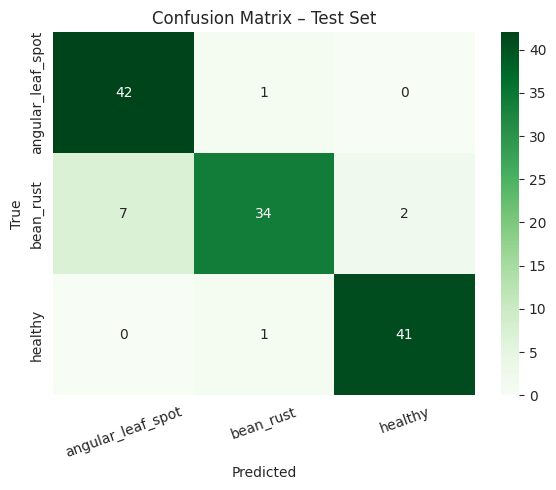

In [20]:
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=3))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens",
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix – Test Set")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

### 4.3 Prediction Function
`predict_image()` takes the path of one image and returns the predicted class, the confidence, and the probability for every class. The same logic is used later in `src/prediction.py` and in the API. Below, it is tested on random test images, comparing the true and predicted labels.

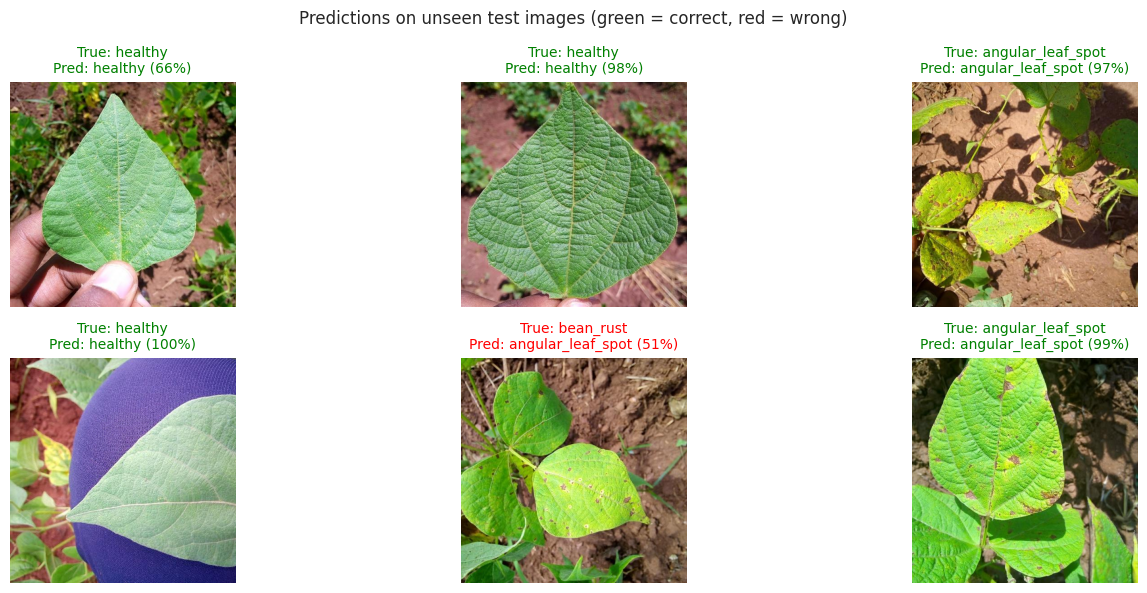

{'predicted_class': 'healthy', 'confidence': 0.6597843766212463, 'probabilities': {'angular_leaf_spot': 0.1936, 'bean_rust': 0.1466, 'healthy': 0.6598}}


In [21]:
def predict_image(model, img_path, class_names=CLASS_NAMES, img_size=IMG_SIZE):
    """Predict the class of a single leaf image."""
    img = tf.keras.utils.load_img(img_path, target_size=img_size)
    arr = tf.keras.utils.img_to_array(img)          # (224, 224, 3), values 0-255
    arr = np.expand_dims(arr, axis=0)               # (1, 224, 224, 3)
    probs = model.predict(arr, verbose=0)[0]        # normalization happens inside the model
    idx = int(np.argmax(probs))
    return {
        "predicted_class": class_names[idx],
        "confidence": float(probs[idx]),
        "probabilities": {c: round(float(p), 4) for c, p in zip(class_names, probs)},
    }

# Test on 6 random test images
test_files = [(f, cls) for cls in CLASS_NAMES for f in glob.glob(f"{TEST_DIR}/{cls}/*.jpg")]
samples = random.sample(test_files, 6)

plt.figure(figsize=(15, 6))
for i, (path, true_cls) in enumerate(samples):
    result = predict_image(loaded_model, path)
    correct = result["predicted_class"] == true_cls
    plt.subplot(2, 3, i + 1)
    plt.imshow(Image.open(path))
    plt.axis("off")
    plt.title(f"True: {true_cls}\nPred: {result['predicted_class']} ({result['confidence']:.0%})",
              color="green" if correct else "red", fontsize=10)
plt.suptitle("Predictions on unseen test images (green = correct, red = wrong)")
plt.tight_layout()
plt.show()

print(predict_image(loaded_model, samples[0][0]))

### 4.4 Evaluation Summary

On the 128 unseen test images, the model reached **91.4% accuracy**, **0.265 loss**, **91.8% precision**, **91.5% recall**, **91.3% F1-score** and **97.9% ROC-AUC**. Training and validation curves stayed close, so the regularization (augmentation, dropout, L2) and early stopping prevented overfitting.

**Per class:**
- **Angular leaf spot** and **healthy** are almost perfect (~98% recall).
- **Bean rust** is the hardest class (79% recall): 7 rust leaves were predicted as angular leaf spot and 2 as healthy. Both diseases show small brown spots, so early rust is easy to confuse with angular leaf spot.

**What this means for farmers:** confusing two diseases is less harmful than missing a disease, and only 2 of 128 sick leaves were called healthy. Low-confidence predictions (like the 51% example above) show the model "knows" when it is unsure, so the app will warn the user to confirm with an agronomist when confidence is below 60%.

**Possible improvements:** more bean rust images (which the retraining feature allows), unfreezing more MobileNetV2 layers, or trying a larger model such as EfficientNet.